# PCLab#7 - Group 4 - Claas Boumans Giuliano Ciaramella Theodor Nissen-Meyer

**20598 – Finance with Big Data, PC Lab #7: Banks, AI Adoption, and Discrimination**

*Time required: approximately __ hours. Difficulty: _ out of 10.*

## 0. Setup
Libraries, the chart theme and helpers of the previous labs. The CFPB file (`complaints.csv.zip`, 365 MB) comes from [consumerfinance.gov](https://www.consumerfinance.gov/data-research/consumer-complaints/). The first run reads it once into `cfpb_cache.pkl` (110 MB); later runs take about 20 seconds.

In [1]:
import os
import pickle
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter
from pandas.api.types import union_categoricals
import seaborn as sns
import statsmodels.formula.api as smf

pd.set_option("display.float_format", "{:,.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)  # pandas' notices on groupby defaults
warnings.filterwarnings("ignore", category=DeprecationWarning)

Z_95 = 1.96  # half width of a 95% interval, in standard errors
RATE_YEARS = range(2012, 2026)  # full calendar years: 2011 has only December, 2026 ends in November

In [2]:
# Chart theme inspired by The Economist: white background, horizontal gridlines,
# bold left-aligned titles, red rule on top, the magazine's blue/teal palette.
ECONOMIST_RED = "#E3120B"
BLUE, CYAN, TEAL, YELLOW = "#006BA2", "#3EBCD2", "#379A8B", "#EBB434"
PURPLE, LIGHT_RED = "#9A607F", "#DB444B"
DARK, GREY, LIGHT_GREY = "#333333", "#758D99", "#C9D3D9"
ECONOMIST_COLORS = [BLUE, CYAN, TEAL, YELLOW, "#B4BA39", PURPLE, "#D1B07C", GREY, LIGHT_RED]
ECONOMIST_BLUES = LinearSegmentedColormap.from_list("economist_blues", ["#F2F8FB", "#C5E4F0", "#3EBCD2", "#006BA2"])
GRID = "#D0D0D0"

plt.rcParams.update({
    "figure.figsize": (14, 5.5),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.prop_cycle": plt.cycler(color=ECONOMIST_COLORS),
    "axes.grid": True,
    "axes.grid.axis": "y",              # horizontal gridlines only
    "grid.color": GRID,
    "axes.axisbelow": True,             # gridlines behind the data
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelcolor": DARK,
    "xtick.color": DARK,
    "ytick.color": DARK,
    "ytick.left": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

In [3]:
WHITE_BOX = {"facecolor": "white", "edgecolor": "none", "pad": 0.5}  # behind a label that crosses a line


def show(title=None):
    '''Add the headline, the red rule and the tag on top of the current figure, then display it.'''
    fig = plt.gcf()
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=15, fontweight="bold")
    fig.tight_layout()
    fig.add_artist(plt.Line2D([0, 1], [1.02, 1.02], transform=fig.transFigure, color=ECONOMIST_RED, lw=1.5))
    fig.add_artist(plt.Rectangle((0, 1.02), 0.035, 0.015, transform=fig.transFigure, color=ECONOMIST_RED,
                                 clip_on=False))
    plt.show()


def vertical_grid(ax):
    '''Vertical gridlines only, for charts read along the x-axis.'''
    ax.grid(False, axis="y")
    ax.grid(True, axis="x", color=GRID)


def annotate(ax, text, xy, offset=(9, 0), **kwargs):
    '''Write `text` next to the point xy, shifted by `offset` points; other arguments go to ax.annotate.'''
    dx = offset[0]
    style = {"ha": "left" if dx > 0 else "right" if dx < 0 else "center", "va": "center", "fontsize": 9.5,
             "color": DARK}
    ax.annotate(text, xy, xytext=offset, textcoords="offset points", **{**style, **kwargs})


def minus_sign(text):
    '''Write a true minus sign in front of numbers.'''
    return re.sub(r"-(?=\d)", "−", text)


POINTS = FuncFormatter(lambda value, _: minus_sign(f"{value * 100:+.1f}"))  # axis in percentage points

## Task #1 – Basic manipulation and descriptive statistics
### 1.1 Load the CFPB complaints
* **No narratives:** the current file has no narrative column, and the CFPB API ignores its `has_narrative` filter. So we keep all complaints, and cannot study their language.
* **Memory:** the file is 5.8 GB unzipped. We read it in chunks, keep text as categories, and keep credit reporting only as counts (1.2 explains why).

In [4]:
CFPB_ZIP = "complaints.csv.zip"  # full CFPB database, downloaded on 10 November 2026
CFPB_CACHE = "cfpb_cache.pkl"  # our compact copy, built once
CHUNK_ROWS = 300_000  # rows per chunk, keeps memory near 1 GB

KEEP_COLUMNS = {  # CFPB name: our name
    "Date received": "date", "Product": "product", "Sub-product": "sub_product", "Issue": "issue",
    "Sub-issue": "sub_issue", "Company": "company", "State": "state", "ZIP code": "zip_raw", "Tags": "tags",
    "Submitted via": "channel", "Company response to consumer": "response", "Timely response?": "timely",
}


def is_credit_reporting(product):
    '''Credit reporting has carried three product names since 2011, all starting the same way.'''
    return product.str.startswith("Credit reporting", na=False)


def clean_zip(raw):
    '''Return the 5 digit ZIP code, or missing when the CFPB masks it (e.g. "123XX") or it is malformed.'''
    zip5 = raw.str.strip().str[:5]
    return zip5.where(zip5.str.fullmatch(r"\d{5}", na=False))


def build_cache(zip_path=CFPB_ZIP, cache_path=CFPB_CACHE):
    '''Read the CFPB file in chunks: other products as rows, credit reporting as counts.'''
    pieces, credit_counts = [], []
    for chunk in pd.read_csv(zip_path, usecols=list(KEEP_COLUMNS), dtype=str, chunksize=CHUNK_ROWS):
        chunk = chunk.rename(columns=KEEP_COLUMNS)
        chunk["date"] = pd.to_datetime(chunk["date"])
        chunk["year"] = chunk["date"].dt.year.astype("int16")
        chunk["zip"] = clean_zip(chunk.pop("zip_raw"))
        chunk["zip_masked"] = chunk["zip"].isna()

        credit = is_credit_reporting(chunk["product"])
        credit_counts.append(chunk[credit].groupby(["year", "zip", "company", "issue"], dropna=False)
                             .size().rename("complaints").reset_index())
        rest = chunk[~credit]
        text_columns = rest.columns.difference(["date", "year", "zip_masked"])
        pieces.append(rest.astype({column: "category" for column in text_columns}))

    # Each chunk has its own categories, so they are merged column by column
    complaints = pd.DataFrame({
        column: (union_categoricals([piece[column] for piece in pieces])
                 if isinstance(pieces[0][column].dtype, pd.CategoricalDtype)
                 else pd.concat([piece[column] for piece in pieces], ignore_index=True))
        for column in pieces[0].columns
    })
    credit_reporting = (pd.concat(credit_counts).groupby(["year", "zip", "company", "issue"], dropna=False)
                        ["complaints"].sum().reset_index())
    with open(cache_path, "wb") as file:
        pickle.dump({"complaints": complaints, "credit_reporting": credit_reporting}, file)


if not os.path.exists(CFPB_CACHE):
    build_cache()
with open(CFPB_CACHE, "rb") as file:
    cache = pickle.load(file)
complaints, credit_reporting = cache["complaints"], cache["credit_reporting"]

n_rest, n_credit = len(complaints), credit_reporting["complaints"].sum()
print(f"All complaints: {n_rest + n_credit:,} ({complaints['date'].min():%b %Y} to {complaints['date'].max():%b %Y}); "
      f"credit reporting {n_credit:,}, other products {n_rest:,}")

All complaints: 19,028,339 (Dec 2011 to Nov 2026); credit reporting 15,675,015, other products 3,353,324


### 1.2 What is credit reporting, and should we consider it?
Credit reporting complaints dispute the files that the credit bureaus keep on a consumer: wrong entries, identity theft, investigations not done.

Against the three bureaus: 94.4%; from the top 1% of ZIP codes: 21.0% (other products: 15.1%)


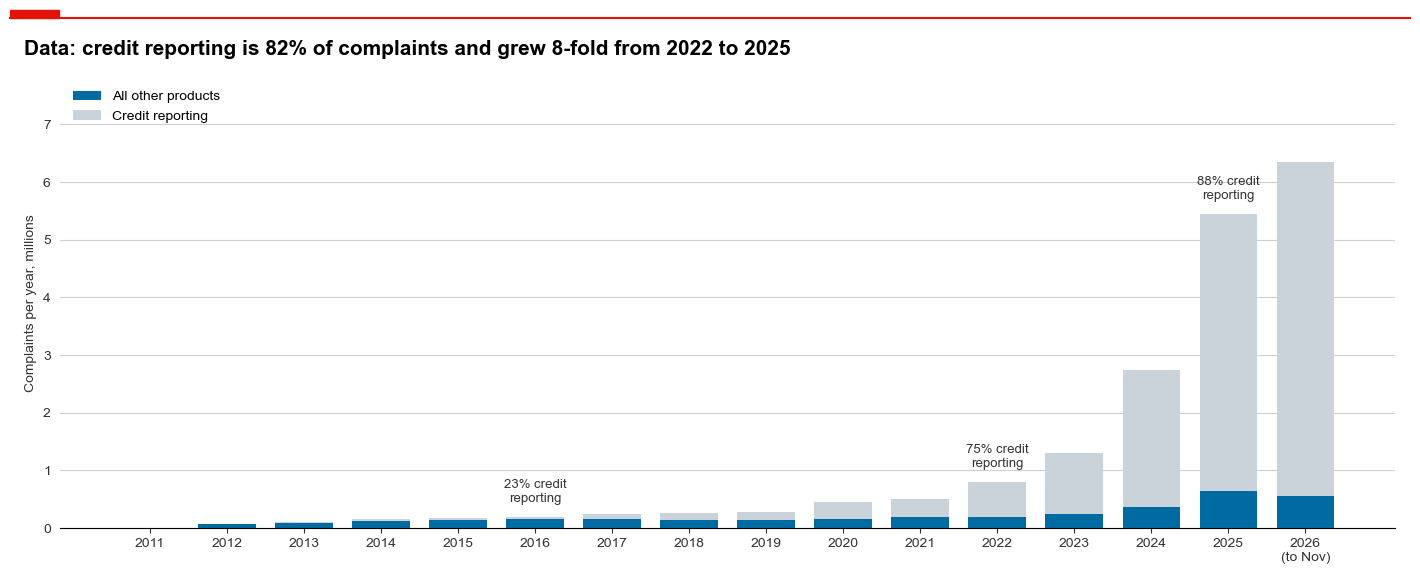

In [5]:
BUREAUS = ["EQUIFAX, INC.", "TRANSUNION INTERMEDIATE HOLDINGS, INC.", "Experian Information Solutions Inc."]


def top_zip_share(counts, share=0.01):
    '''Share of complaints that come from the top `share` of ZIP codes.'''
    counts = counts.sort_values(ascending=False)
    return counts.head(int(len(counts) * share)).sum() / counts.sum()


credit_per_year = credit_reporting.groupby("year")["complaints"].sum()
rest_per_year = complaints.groupby("year").size()
bureau_share = credit_reporting.loc[credit_reporting["company"].isin(BUREAUS), "complaints"].sum() / n_credit
credit_by_zip = credit_reporting.groupby("zip", observed=True)["complaints"].sum()
print(f"Against the three bureaus: {bureau_share:.1%}; from the top 1% of ZIP codes: "
      f"{top_zip_share(credit_by_zip):.1%} (other products: {top_zip_share(complaints.groupby('zip', observed=True).size()):.1%})")

fig, ax = plt.subplots()
years = rest_per_year.index
ax.bar(years, rest_per_year / 1e6, color=BLUE, width=0.75, label="All other products")
ax.bar(years, credit_per_year.reindex(years, fill_value=0) / 1e6, bottom=rest_per_year / 1e6, color=LIGHT_GREY,
       width=0.75, label="Credit reporting")
for year in [2016, 2022, 2025]:
    total = rest_per_year[year] + credit_per_year[year]
    annotate(ax, f"{credit_per_year[year] / total:.0%} credit\nreporting", (year, total / 1e6), offset=(0, 18))
ax.set_ylim(0, 7.8)  # room for the labels
ax.set_xticks(years, [str(year) if year < 2026 else "2026\n(to Nov)" for year in years])
ax.set_ylabel("Complaints per year, millions")
ax.legend(loc="upper left")
growth = credit_per_year[2025] / credit_per_year[2022]
show(f"Data: credit reporting is {n_credit / (n_rest + n_credit):.0%} of complaints and grew {growth:.0f}-fold from 2022 to 2025")

**Comments – 1.2: Not for Tasks #2 and #3.**
* **It measures bureaus, not banks:** 94.4% targets Equifax, Experian or TransUnion.
* **Its volume measures who files:** no change in credit markets matches the 8-fold rise, and the top 1% of ZIP codes file 21.0% of it (15.1% for other products). This fits credit repair firms that send template disputes in bulk.

### 1.3 What are the main issues?
The CFPB renamed its products in 2017 and 2023, so we merge the names into nine groups.

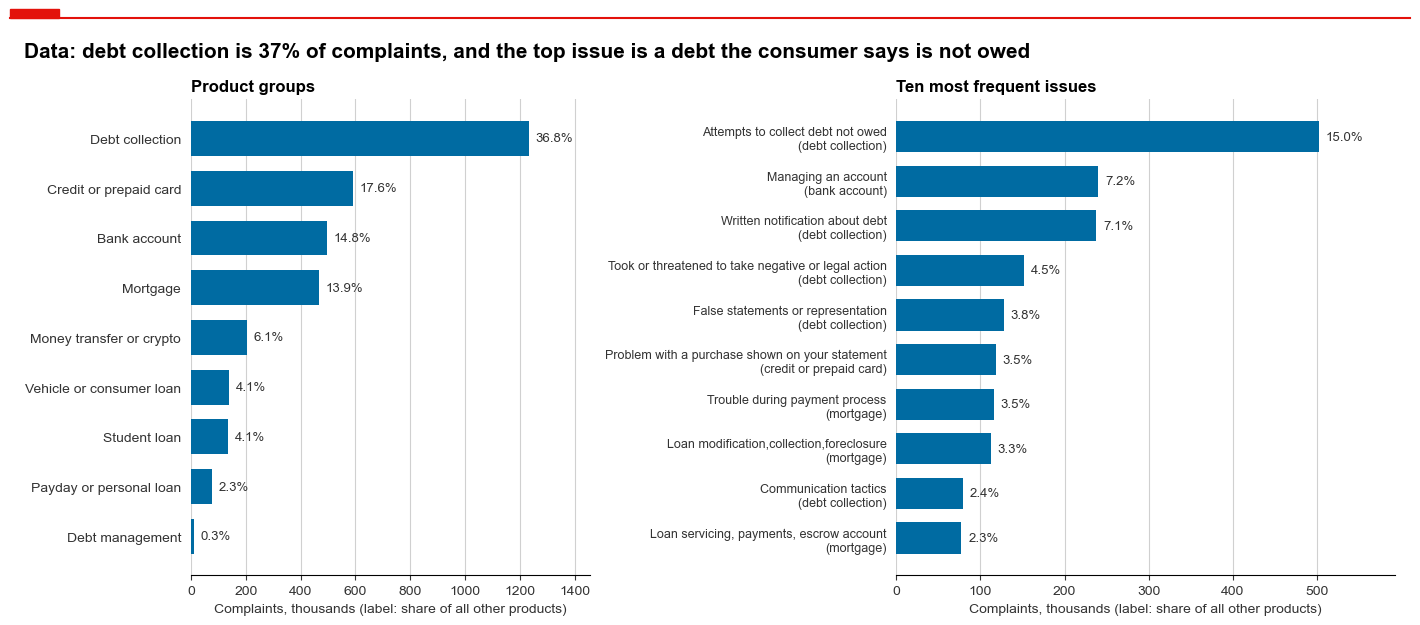

In [6]:
PRODUCT_GROUPS = {  # CFPB product name: our group
    "Debt collection": "Debt collection",
    "Mortgage": "Mortgage",
    "Checking or savings account": "Bank account",
    "Bank account or service": "Bank account",
    "Credit card": "Credit or prepaid card",
    "Credit card or prepaid card": "Credit or prepaid card",
    "Prepaid card": "Credit or prepaid card",
    "Money transfer, virtual currency, or money service": "Money transfer or crypto",
    "Money transfers": "Money transfer or crypto",
    "Virtual currency": "Money transfer or crypto",
    "Other financial service": "Money transfer or crypto",
    "Student loan": "Student loan",
    "Vehicle loan or lease": "Vehicle or consumer loan",
    "Consumer Loan": "Vehicle or consumer loan",
    "Payday loan": "Payday or personal loan",
    "Payday loan, title loan, or personal loan": "Payday or personal loan",
    "Payday loan, title loan, personal loan, or advance loan": "Payday or personal loan",
    "Debt or credit management": "Debt management",
}

complaints["product_group"] = complaints["product"].astype(str).map(PRODUCT_GROUPS).astype("category")
assert complaints["product_group"].notna().all()  # every product name has a group

product_counts = complaints["product_group"].value_counts()
issue_counts = complaints["issue"].value_counts().head(10)
issue_product = complaints.groupby("issue", observed=True)["product_group"].agg(lambda x: x.value_counts().index[0])

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.25]})
for ax, counts, title in [(axes[0], product_counts, "Product groups"),
                          (axes[1], issue_counts, "Ten most frequent issues")]:
    counts = counts.iloc[::-1]
    labels = counts.index if ax is axes[0] else [f"{issue[:52]}\n({issue_product[issue].lower()})"
                                                 for issue in counts.index]
    ax.barh(labels, counts.values / 1e3, color=BLUE, height=0.7)
    for row, value in enumerate(counts.values):
        annotate(ax, f"{value / n_rest:.1%}", (value / 1e3, row), offset=(5, 0))
    ax.set_xlim(0, counts.max() / 1e3 * 1.18)  # room for the labels
    ax.set_xlabel("Complaints, thousands (label: share of all other products)")
    ax.set_title(title, fontsize=12)
    vertical_grid(ax)
axes[1].tick_params(axis="y", labelsize=9)
show(f"Data: debt collection is {product_counts.iloc[0] / n_rest:.0%} of complaints, "
     "and the top issue is a debt the consumer says is not owed")

### 1.4 Merge with the ZIP code data
* **Year:** each complaint gets the ACS 5 year estimate of its year; 2024 to 2026 get 2023.
* **Income brackets:** quartiles of ZIP code median income, **weighted by households** and redrawn every year, so each holds a quarter of US households. Minority quartiles (share of Black and Hispanic residents) follow the same rule.
* **Masked ZIP codes:** the CFPB shows only "123XX" for ZIP codes under 20,000 people, so rural areas are under-represented.

In [7]:
CENSUS_FILE = "US_Census_Clean_Nov2025/income_combined_2011-2023.csv"  # one row per ZIP code and year
CENSUS_COLUMNS = {
    "ZIP CODE": "zip", "Year": "census_year", "NUMBER OF HOUSEHOLDS": "households",
    "MEDIAN INCOME GENERAL": "median_income", "PERCENTAGE BLACK": "pct_black",
    "PERCENTAGE HISPANIC/LATINO ORIGIN (OF ANY RACE)": "pct_hispanic", "PERCENTAGE HOUSEHOLDER 65+ YO": "pct_65plus",
}
OPEN_ENDED = {"250,000+": "250000", "2,500-": "2500"}  # medians beyond the top or bottom interval: we keep the bound
QUARTILE_NAMES = {1: "Q1 poorest", 2: "Q2", 3: "Q3", 4: "Q4 richest"}


def load_census(path=CENSUS_FILE):
    '''Read the ZIP panel: "-" and "(X)" become missing values, open ended medians their bound.'''
    census = pd.read_csv(path, usecols=list(CENSUS_COLUMNS), dtype=str).rename(columns=CENSUS_COLUMNS)
    census["zip"] = census["zip"].str.replace("ZCTA5 ", "", regex=False)
    census["median_income"] = census["median_income"].replace(OPEN_ENDED)
    numeric = census.columns.drop("zip")
    census[numeric] = census[numeric].apply(lambda column: pd.to_numeric(column.str.replace(",", ""), errors="coerce"))
    # Hispanic is "of any race", so a Black Hispanic counts twice: the sum is capped at 100
    census["pct_minority"] = (census["pct_black"] + census["pct_hispanic"]).clip(upper=100)
    return census[census["households"].gt(0) & census["median_income"].notna()]


def weighted_quartile(values, weights):
    '''Quartile (1 to 4) of each value, such that every quartile holds a quarter of the weights.'''
    weights = weights[values.index]
    order = values.sort_values().index
    cumulative = weights[order].cumsum() - weights[order] / 2  # midpoint of each ZIP code's slice
    return (np.floor(cumulative / weights.sum() * 4).astype(int) + 1).reindex(values.index)


def add_census(table):
    '''Give each complaint (or count) the census data of its ZIP code and year.'''
    table = table.assign(zip=table["zip"].astype(object), census_year=table["year"].clip(2011, 2023).astype(int))
    return table.merge(census, on=["zip", "census_year"], how="left", validate="many_to_one")


census = load_census()
assert not census.duplicated(["zip", "census_year"]).any()
by_year = census.groupby("census_year", group_keys=False)
census["income_q"] = by_year.apply(lambda year: weighted_quartile(year["median_income"], year["households"]))
census["minority_q"] = by_year.apply(lambda year: weighted_quartile(year["pct_minority"].dropna(), year["households"]))

complaints = add_census(complaints)
credit_reporting = add_census(credit_reporting)
matched = complaints["income_q"].notna()
assert len(complaints) == n_rest  # the merge adds no rows
print(f"With census data: {matched.mean():.1%} of complaints ({complaints['zip_masked'].mean():.1%} masked, "
      f"{complaints.loc[~complaints['zip_masked'], 'income_q'].notna().mean():.1%} of full ZIP codes match)")
print("Median income of the median ZIP code, 2023:",
      census.query("census_year == 2023").groupby("income_q")["median_income"].median().rename(QUARTILE_NAMES)
      .map("${:,.0f}".format).to_dict())

With census data: 86.2% of complaints (12.7% masked, 98.7% of full ZIP codes match)
Median income of the median ZIP code, 2023: {'Q1 poorest': '$50,542', 'Q2': '$68,487', 'Q3': '$86,250', 'Q4 richest': '$121,250'}


### 1.5 An interesting fact: relief has halved since 2023
The share of complaints closed with **monetary relief** (money back) is our measure of service quality in Task #3. We also hold the product mix fixed, as debt collection, which almost never pays, has grown fast since 2023. We start in 2014, the first year with all major products.

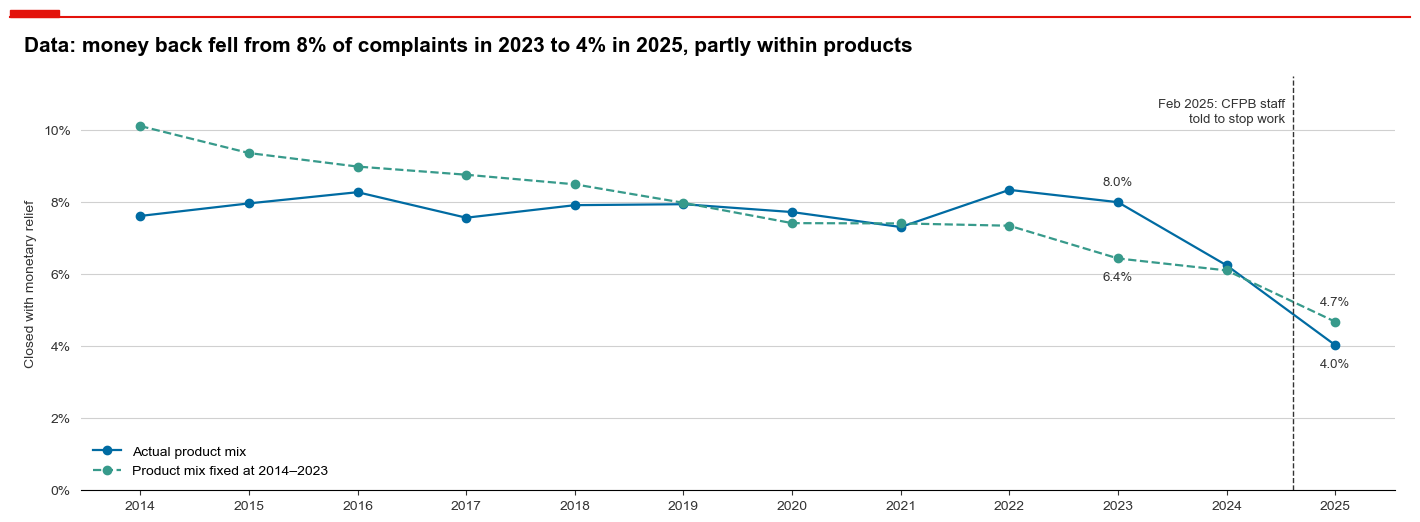

In [8]:
CFPB_FREEZE = pd.Timestamp("2025-02-10")  # the acting director orders CFPB staff to stop most work
TREND_START = 2014  # the CFPB takes debt collection complaints only from July 2013

# "In progress" and the labels of 2011 to 2013 ("Closed with relief") say nothing on the kind of relief
complaints["closed"] = complaints["response"].isin(
    ["Closed with monetary relief", "Closed with non-monetary relief", "Closed with explanation"])
complaints["relief"] = complaints["response"].eq("Closed with monetary relief").astype(float)
trend = complaints[complaints["closed"] & complaints["year"].between(TREND_START, RATE_YEARS[-1])]

relief_by_year = trend.groupby("year")["relief"].mean()
cells = trend.groupby(["year", "product_group"], observed=True)["relief"].mean().unstack()
mix = trend[trend["year"] <= 2023]["product_group"].value_counts(normalize=True)
fixed_mix = (cells[mix.index] * mix).sum(axis=1) / cells[mix.index].notna().mul(mix).sum(axis=1)

fig, ax = plt.subplots(figsize=(14, 5))
middle = relief_by_year.index + 0.5  # points in the middle of their year, so the date line falls in place
ax.plot(middle, relief_by_year, color=BLUE, marker="o", label="Actual product mix")
ax.plot(middle, fixed_mix, color=TEAL, marker="o", ls="--", label=f"Product mix fixed at {TREND_START}–2023")
freeze = CFPB_FREEZE.year + CFPB_FREEZE.dayofyear / 365
ax.axvline(freeze, color=DARK, ls="--", lw=1)
annotate(ax, "Feb 2025: CFPB staff\ntold to stop work", (freeze, 0.105), offset=(-6, 0), ha="right", bbox=WHITE_BOX)
for year, series, shift in [(2023, relief_by_year, 14), (2025, relief_by_year, -14), (2023, fixed_mix, -14),
                            (2025, fixed_mix, 14)]:
    annotate(ax, f"{series[year]:.1%}", (year + 0.5, series[year]), offset=(0, shift))
ax.set_xticks(middle, relief_by_year.index)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.115)
ax.set_ylabel("Closed with monetary relief")
ax.legend(loc="lower left")
show(f"Data: money back fell from {relief_by_year[2023]:.0%} of complaints in 2023 to {relief_by_year[2025]:.0%} in 2025, "
     "partly within products")

**Comments – 1.5**
* **Stable for a decade, then halved:** 7.3% to 8.3% from 2014 to 2023, 4.0% in 2025. At a fixed product mix, relief falls from 6.4% to 4.7%, so the surge of debt collection explains only part of it (within products, relief has drifted down since 2014: 10.1%).
* **The fall coincides with the CFPB's 2025 retreat** (a correlation, not a test). For Task #3: every comparison holds the year fixed.

## Task #2 – Heterogeneity across income brackets
From here on: complaints outside credit reporting with census data, full years 2012 to 2025.

### 2.1 How often each income quartile complains

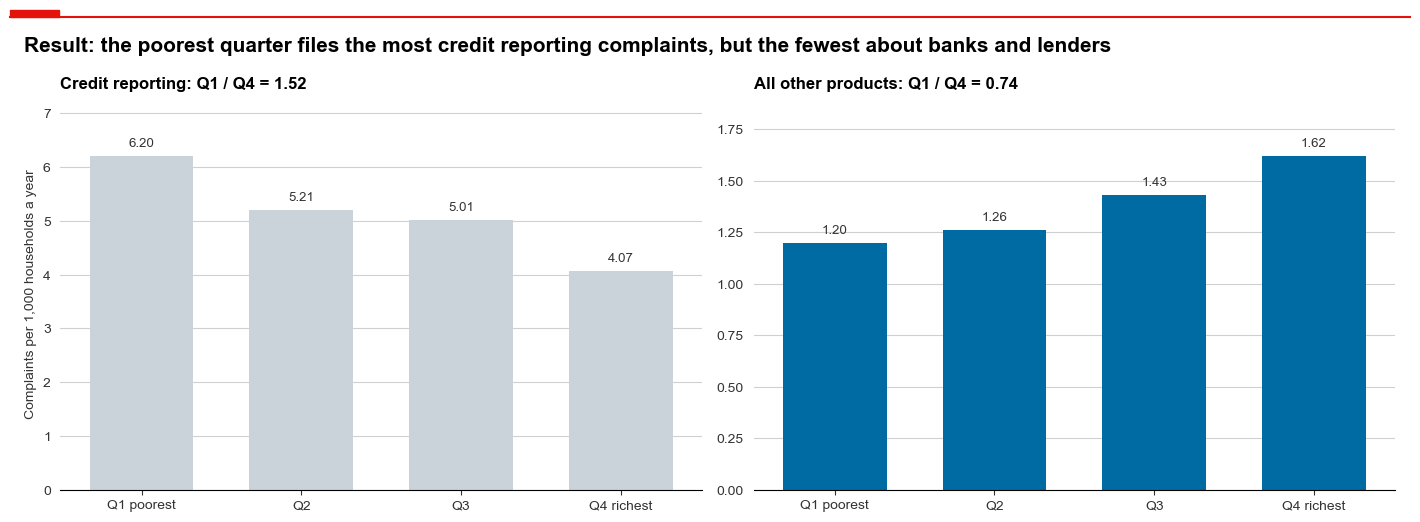

In [9]:
def rate_per_household(table, quartile_column, weights=None):
    '''Complaints per 1,000 households a year, by quartile, averaged over the full years.'''
    table = table[table["year"].isin(RATE_YEARS)]
    counts = (table.groupby(["year", quartile_column])[weights].sum() if weights
              else table.groupby(["year", quartile_column]).size())
    households = census.groupby(["census_year", quartile_column])["households"].sum()
    census_year = counts.index.get_level_values("year").to_series().clip(upper=2023).values  # its census year
    keys = list(zip(census_year, counts.index.get_level_values(quartile_column)))
    return (counts / households.loc[keys].values * 1000).groupby(quartile_column).mean()


bank_sample = complaints[matched]
rates = pd.DataFrame({
    "Credit reporting": rate_per_household(credit_reporting, "income_q", weights="complaints"),
    "All other products": rate_per_household(bank_sample, "income_q"),
}).rename(index=QUARTILE_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, column, color in zip(axes, rates.columns, [LIGHT_GREY, BLUE]):
    bars = ax.bar(rates.index, rates[column], color=color, width=0.65)
    for bar, value in zip(bars, rates[column]):
        annotate(ax, f"{value:.2f}", (bar.get_x() + bar.get_width() / 2, value), offset=(0, 9))
    ax.set_title(f"{column}: Q1 / Q4 = {rates[column].iloc[0] / rates[column].iloc[-1]:.2f}", fontsize=12)
    ax.set_ylim(0, rates[column].max() * 1.18)
axes[0].set_ylabel("Complaints per 1,000 households a year")
show("Result: the poorest quarter files the most credit reporting complaints, but the fewest about banks and lenders")

**Comment – 2.1:** fewer complaints need not mean better service, since poorer households hold fewer cards, mortgages and accounts. 2.2 and 2.3 therefore compare **shares within each quartile**.

### 2.2 Products and sub-products
Q1 / Q4 = how much more often the poorest quarter complains about a product than the richest. The table lists the sub-products (at least 5,000 complaints) at both ends.

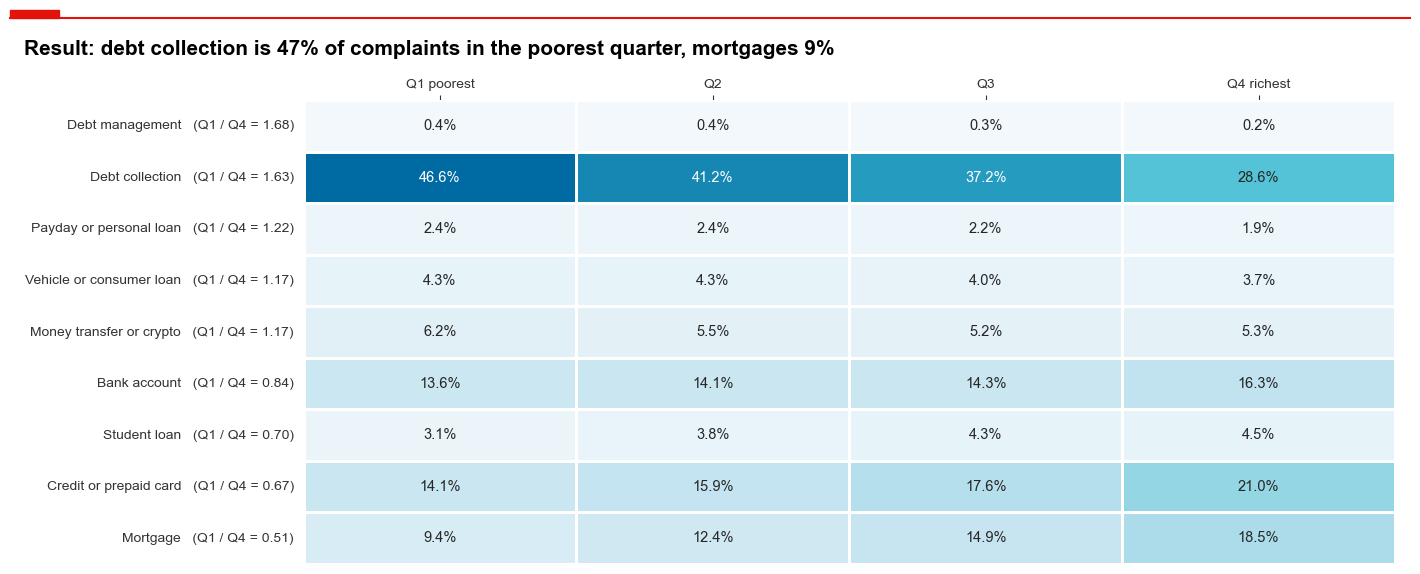

income_q,Q1 poorest,Q4 richest,Q1 / Q4,complaints
sub_product,,,,
Debt collection: I do not know,22.3%,10.6%,2.11,"467,556"
Debt collection: Auto debt,1.3%,0.7%,2.03,"28,454"
Credit or prepaid card: Government benefit card,0.5%,0.3%,1.80,"11,865"
Debt collection: Telecommunications debt,1.3%,0.7%,1.76,"28,648"
Bank account: CD (Certificate of Deposit),0.1%,0.4%,0.40,"6,836"
Mortgage: Home equity loan or line of credit (HELOC),0.2%,0.6%,0.38,"12,547"
Mortgage: Home equity loan or line of credit,0.2%,0.6%,0.37,"10,700"
Mortgage: Conventional adjustable mortgage (ARM),0.4%,1.3%,0.32,"23,445"


In [10]:
MIN_COMPLAINTS = 5_000  # labels below this are too small to compare by quartile
TABLE_FORMAT = {"Q1 poorest": "{:.1%}", "Q4 richest": "{:.1%}", "Q1 / Q4": "{:.2f}", "complaints": "{:,}"}


def shares_by_quartile(table, column):
    '''Share of each value of `column` within each income quartile, the ratio of Q1 to Q4, and the count.'''
    shares = pd.crosstab(table[column], table["income_q"], normalize="columns").rename(columns=QUARTILE_NAMES)
    shares["Q1 / Q4"] = shares["Q1 poorest"] / shares["Q4 richest"]
    shares["complaints"] = table[column].value_counts()
    return shares[shares["complaints"] >= MIN_COMPLAINTS].sort_values("Q1 / Q4", ascending=False)


def extremes(shares, top=4):
    '''The labels most over- and under-represented in Q1.'''
    return pd.concat([shares.head(top), shares.tail(top)])[list(TABLE_FORMAT)].style.format(TABLE_FORMAT)


product_shares = shares_by_quartile(bank_sample, "product_group")

fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(product_shares[list(QUARTILE_NAMES.values())], annot=True, fmt=".1%", cmap=ECONOMIST_BLUES, cbar=False,
            linewidths=1, ax=ax, annot_kws={"fontsize": 10.5})
ax.set_yticklabels([f"{group}   (Q1 / Q4 = {ratio:.2f})" for group, ratio in product_shares["Q1 / Q4"].items()],
                   rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", top=True, labeltop=True, bottom=False, labelbottom=False)
ax.grid(False)
show(f"Result: debt collection is {product_shares.loc['Debt collection', 'Q1 poorest']:.0%} of complaints in the poorest quarter, "
     f"mortgages {product_shares.loc['Mortgage', 'Q1 poorest']:.0%}")

sub_products = bank_sample.assign(sub_product=bank_sample["product_group"].astype(str) + ": "
                                  + bank_sample["sub_product"].astype(str))
extremes(shares_by_quartile(sub_products, "sub_product"))

**Comment – 2.2:** the poor complain about debt (debt collection 46.6% of Q1 against 28.6% of Q4, above all debts they cannot name), the rich about the products of wealth (mortgages 9.4% against 18.5%, home equity lines, CDs).

### 2.3 Issues and sub-issues

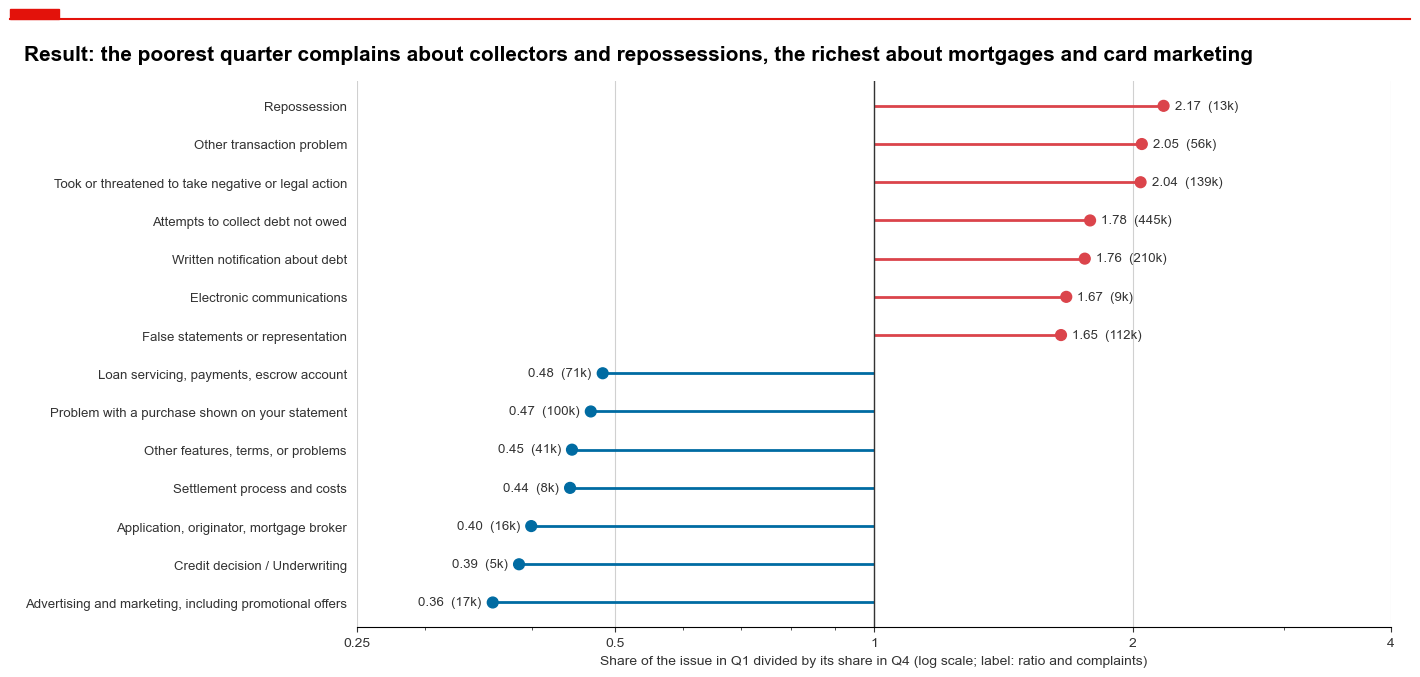

income_q,Q1 poorest,Q4 richest,Q1 / Q4,complaints
sub_issue,,,,
Loan balance remaining after the vehicle is repossessed and sold,0.4%,0.2%,2.21,"5,557"
Threatened or suggested your credit would be damaged,7.0%,3.6%,1.98,"112,102"
Was not notified of investigation status or results,1.3%,0.7%,1.78,"20,705"
Notification didn't disclose it was an attempt to collect a debt,3.0%,1.8%,1.68,"55,249"
Credit card company isn't resolving a dispute about a purchase on your statement,2.0%,5.1%,0.39,"72,263"
Didn't receive advertised or promotional terms,0.2%,0.8%,0.27,"9,703"
Didn't receive terms that were advertised,0.2%,0.7%,0.26,"8,910"
Problem with rewards from credit card,0.2%,0.9%,0.18,"9,966"


In [11]:
TOP_ISSUES = 7  # issues per side of the chart

issue_shares = shares_by_quartile(bank_sample, "issue")
shown = pd.concat([issue_shares.head(TOP_ISSUES), issue_shares.tail(TOP_ISSUES)]).iloc[::-1]

fig, ax = plt.subplots(figsize=(14, 6.5))
rows = np.arange(len(shown))
colors = [BLUE if ratio < 1 else LIGHT_RED for ratio in shown["Q1 / Q4"]]
ax.hlines(rows, 1, shown["Q1 / Q4"], color=colors, lw=2)
ax.scatter(shown["Q1 / Q4"], rows, color=colors, s=60, zorder=3)
for row, (ratio, count) in enumerate(zip(shown["Q1 / Q4"], shown["complaints"])):
    annotate(ax, f"{ratio:.2f}  ({count / 1e3:,.0f}k)", (ratio, row), offset=(8 if ratio > 1 else -8, 0))
ax.axvline(1, color=DARK, lw=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"])
ax.set_xlim(0.25, 4)
ax.set_yticks(rows, [issue[:75] for issue in shown.index], fontsize=9.5)
ax.set_xlabel("Share of the issue in Q1 divided by its share in Q4 (log scale; label: ratio and complaints)")
vertical_grid(ax)
show("Result: the poorest quarter complains about collectors and repossessions, the richest about mortgages and card marketing")

extremes(shares_by_quartile(bank_sample, "sub_issue"))

**Comments – 2.3: Which complaint types are most frequent among lower income customers?**
* **Most frequent:** "Attempts to collect debt not owed", 19.9% of Q1's complaints.
* **Most over-represented:** repossession (2.17 times its Q4 share), collectors threatening legal action (2.04) or, as a sub-issue, credit damage (1.98). The poor meet their banks in the most adversarial conversations, where a chatbot's tone matters most.

## Task #3 – Replication of Begley and Purnanandam (2021)
Begley and Purnanandam (2021) find that ZIP codes with more minority residents file more complaints, **even at the same income and education**, and read this as worse financial services.

### 3.A Baseline: summary statistics
Table 1 describes ZIP codes with at least 500 households (averages over census years, complaints of 2012 to 2025). We could not access the published table, so we compare patterns, not numbers.

In [12]:
MIN_HOUSEHOLDS = 500  # smaller ZIP codes give unstable rates
N_YEARS = len(RATE_YEARS)
RATE = "complaints per 1,000 households a year"
TABLE_1_NAMES = {"median_income": "median household income ($)", "pct_black": "Black residents (%)",
                 "pct_hispanic": "Hispanic residents (%)", "pct_minority": "Black or Hispanic residents (%)",
                 "pct_65plus": "householder aged 65+ (%)"}

in_years = bank_sample[bank_sample["year"].isin(RATE_YEARS)]
zip_counts = pd.crosstab(in_years["zip"], in_years["product_group"])
zip_table = census.groupby("zip")[["households", *TABLE_1_NAMES]].mean().query("households >= @MIN_HOUSEHOLDS")
zip_table["complaints"] = zip_counts.sum(axis=1).reindex(zip_table.index, fill_value=0)
zip_table[RATE] = zip_table["complaints"] / zip_table["households"] / N_YEARS * 1000
product_share = zip_counts.div(zip_counts.sum(axis=1), axis=0).add_prefix("share: ").reindex(zip_table.index)

table_1 = zip_table.join(product_share).rename(columns=TABLE_1_NAMES).describe().T
tags = in_years["tags"].astype(str)
print(f"Complaints: {len(in_years):,}; tagged older American {tags.str.contains('Older').mean():.1%}, "
      f"servicemember {tags.str.contains('Servicemember').mean():.1%}; online {in_years['channel'].eq('Web').mean():.1%}; "
      f"monetary relief {in_years.loc[in_years['closed'], 'relief'].mean():.1%}")
table_1[["count", "mean", "std", "25%", "50%", "75%"]].style.format("{:,.2f}").format("{:,.0f}", subset=["count"])

Complaints: 2,394,527; tagged older American 6.6%, servicemember 7.9%; online 81.8%; monetary relief 6.9%


,count,mean,std,25%,50%,75%
households,"21,380","5,554.55","5,702.72","1,165.54","3,127.23","8,589.37"
median household income ($),"21,380","61,989.09","25,567.24","45,362.77","56,046.12","72,108.37"
Black residents (%),"21,380",9.01,16.34,0.32,1.84,9.38
Hispanic residents (%),"21,380",8.98,16.01,1.22,2.99,8.57
Black or Hispanic residents (%),"21,380",17.94,22.94,2.25,7.82,24.77
householder aged 65+ (%),"21,380",26.82,7.84,22.20,26.76,30.98
complaints,"21,380",111.50,200.94,5.00,22.00,135.00
"complaints per 1,000 households a year","21,380",0.89,0.96,0.27,0.57,1.18
share: Bank account,"20,663",0.15,0.15,0.06,0.13,0.20
share: Credit or prepaid card,"20,663",0.18,0.17,0.08,0.17,0.25


Minority areas are poorer on average, so we plot complaints against minority share **within each income quartile**, then hold income, age and state fixed in a regression across ZIP codes (log of 1 + rate, weighted by households, HC1 errors).

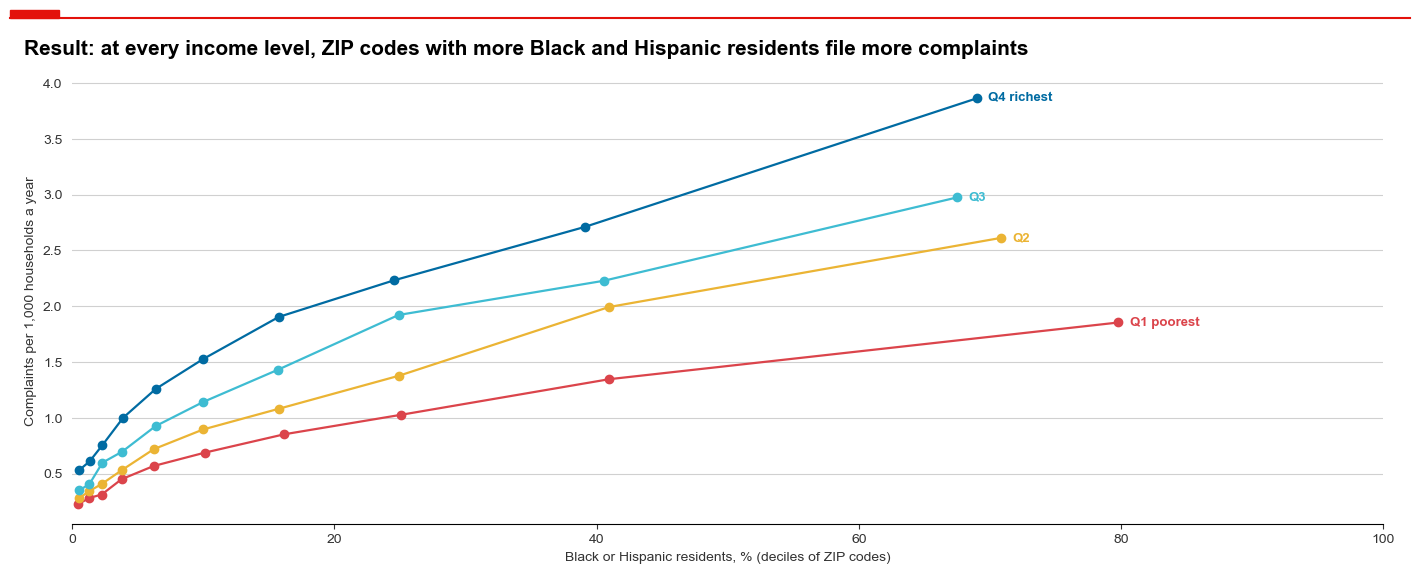

+10 points Black: +13.9% complaints (t = 68.8)
+10 points Hispanic: +2.9% complaints (t = 15.5)
+10% income: +4.1% complaints (t = 50.2)


In [13]:
DECILES = 10  # bins of minority share

zip_table["income_q"] = weighted_quartile(zip_table["median_income"], zip_table["households"]).map(QUARTILE_NAMES)
zip_table["minority_bin"] = pd.qcut(zip_table["pct_minority"].rank(method="first"), DECILES, labels=False)
bins = zip_table.groupby(["income_q", "minority_bin"], observed=True).apply(
    lambda g: pd.Series({"rate": g["complaints"].sum() / g["households"].sum() / N_YEARS * 1000,
                         "minority": np.average(g["pct_minority"], weights=g["households"])}))

fig, ax = plt.subplots()
for (quartile, group), color in zip(bins.groupby(level=0), [LIGHT_RED, YELLOW, CYAN, BLUE]):
    ax.plot(group["minority"], group["rate"], marker="o", color=color)
    annotate(ax, quartile, (group["minority"].iloc[-1], group["rate"].iloc[-1]), offset=(8, 0), color=color,
             fontweight="bold")
ax.set_xlim(0, 100)
ax.set_xlabel("Black or Hispanic residents, % (deciles of ZIP codes)")
ax.set_ylabel(RATE.capitalize())
show("Result: at every income level, ZIP codes with more Black and Hispanic residents file more complaints")

# The state with most of the ZIP code's complaints (a ZIP code can cross a state line)
state_counts = in_years.groupby(["zip", "state"], observed=True).size().sort_values()
zip_table["state"] = state_counts.reset_index().drop_duplicates("zip", keep="last").set_index("zip")["state"].astype(str)
zip_table["log_rate"] = np.log1p(zip_table[RATE])
zip_table["log_income"] = np.log(zip_table["median_income"])
data = zip_table.dropna(subset=["state", "pct_black"])
zip_model = smf.wls("log_rate ~ pct_black + pct_hispanic + log_income + pct_65plus + C(state)", data=data,
                    weights=data["households"]).fit(cov_type="HC1")
for name, label, step in [("pct_black", "+10 points Black", 10), ("pct_hispanic", "+10 points Hispanic", 10),
                          ("log_income", "+10% income", np.log(1.1))]:
    print(f"{label}: {np.expm1(zip_model.params[name] * step):+.1%} complaints (t = {zip_model.tvalues[name]:.1f})")

More complaints could also mean a readier habit of complaining. The company's response separates the two: we compare monetary relief across minority quartiles **within the same company, product and year** (cells weighted by complaints, HC1 errors).

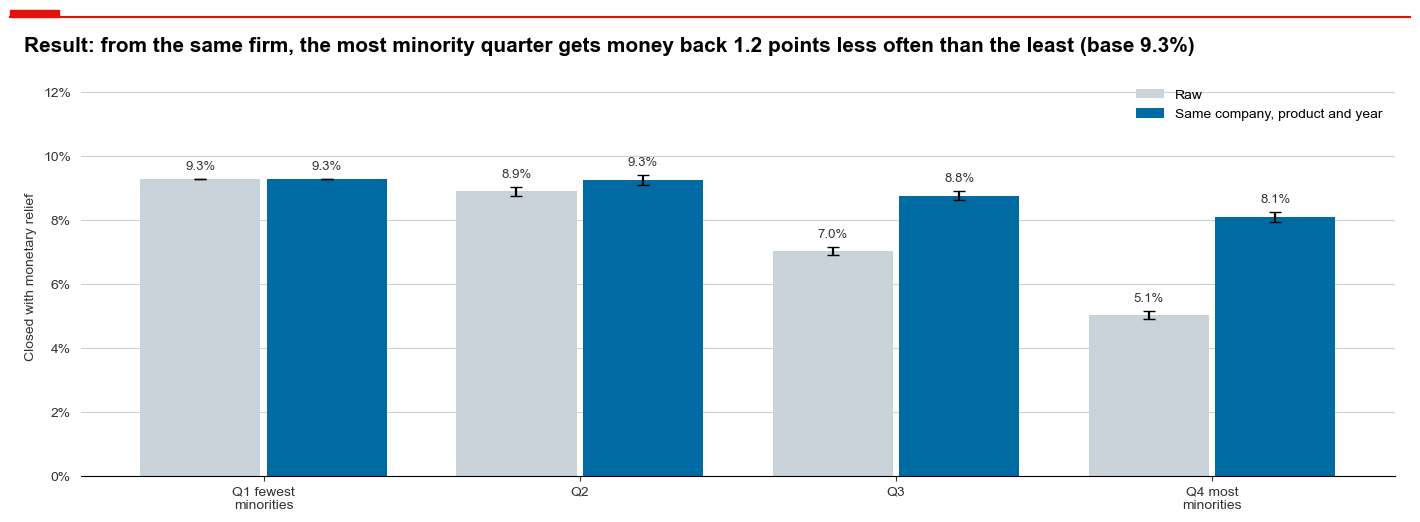

In [14]:
MINORITY_NAMES = {1: "Q1 fewest\nminorities", 2: "Q2", 3: "Q3", 4: "Q4 most\nminorities"}


def minority_gaps(table, cell_columns):
    '''
    Relief gap of minority quartiles Q2 to Q4 against Q1, within cells of `cell_columns` (none: raw gap).
    Demeaning within cells replaces thousands of fixed effects. Returns the gap and its standard error.
    '''
    table = table[table["closed"]].dropna(subset=["minority_q"])
    if not cell_columns:  # raw gap: difference of means, with the error of two proportions
        rates = table.groupby("minority_q")["relief"].agg(["mean", "size"])
        variance = rates["mean"] * (1 - rates["mean"]) / rates["size"]
        return pd.DataFrame({"gap": rates["mean"] - rates.loc[1, "mean"],
                             "error": np.sqrt(variance + variance[1])}).loc[[2, 3, 4]]
    cell = pd.Series("", index=table.index)
    for column in cell_columns:
        cell = cell + "|" + table[column].astype(str)
    cells = table.groupby([cell.rename("cell"), "minority_q"])["relief"].agg(["mean", "size"]).reset_index()
    dummies = [f"q{quartile}" for quartile in (2, 3, 4)]
    for quartile, name in zip((2, 3, 4), dummies):
        cells[name] = (cells["minority_q"] == quartile) * 1.0
    total = cells.groupby("cell")["size"].transform("sum")
    for column in ["mean", *dummies]:
        cells[column] -= (cells[column] * cells["size"]).groupby(cells["cell"]).transform("sum") / total
    model = smf.wls(f"mean ~ {' + '.join(dummies)} - 1", data=cells, weights=cells["size"]).fit(cov_type="HC1")
    return pd.DataFrame({"gap": model.params.values, "error": model.bse.values}, index=[2, 3, 4])


SAME_FIRM = ["company", "product_group", "year"]
raw_gaps, firm_gaps = minority_gaps(in_years, []), minority_gaps(in_years, SAME_FIRM)
base_rate = in_years.loc[in_years["closed"] & (in_years["minority_q"] == 1), "relief"].mean()

fig, ax = plt.subplots(figsize=(14, 5))
positions = np.arange(4)
for shift, gaps, label, color in [(-0.2, raw_gaps, "Raw", LIGHT_GREY),
                                  (0.2, firm_gaps, "Same company, product and year", BLUE)]:
    values = base_rate + np.r_[0, gaps["gap"]]
    errors = Z_95 * np.r_[0, gaps["error"]]
    ax.bar(positions + shift, values, width=0.38, color=color, yerr=errors, capsize=4, label=label)
    for position, value, error in zip(positions + shift, values, errors):
        annotate(ax, f"{value:.1%}", (position, value + error), offset=(0, 9))
ax.set_xticks(positions, MINORITY_NAMES.values())
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.125)
ax.set_ylabel("Closed with monetary relief")
ax.legend(loc="upper right")
show(f"Result: from the same firm, the most minority quarter gets money back "
     f"{-firm_gaps.loc[4, 'gap'] * 100:.1f} points less often than the least (base {base_rate:.1%})")

**Comments – 3.A**
* **The pattern of Begley and Purnanandam (2021) holds:** in every income quartile complaints rise with minority share. At the same income, age and state, 10 points more Black residents mean +13.9% complaints (Hispanic +2.9%), while 10% more income means +4.1%. So the minority effect is not poverty in disguise.
* **It is not only a habit of complaining:** within the same company, product and year, relief still falls with minority share, to −1.18 points in Q4 against a Q1 base of 9.3%. About 72% of the raw gap (−4.23) comes from which firms and products minorities deal with. **The within-firm gap is our measure of unequal service in 3.B.**

### 3.B The role of technology
#### 3.B.1 FinTech against traditional lenders
We use the classification of mortgage lenders in Appendix A1 of Buchak et al. (2018): **FinTech** if nearly the whole application runs online without a human (e.g. Quicken Loans), **shadow bank** for other non-banks, **traditional bank** for depository institutions. We match CFPB names by pattern, including renamed firms (Quicken Loans → Rocket Mortgage, loanDepot → LD Holdings, Nationstar → Mr. Cooper), and move SunTrust to the banks, since it was a depository institution.

Classified: 60.4% of 381,604 mortgage complaints; FinTech 6,106, of which Rocket Mortgage 65.6%
Share from the highest minority quartile: {'FinTech': '26.5%', 'Shadow bank': '29.4%', 'Traditional bank': '29.4%'}


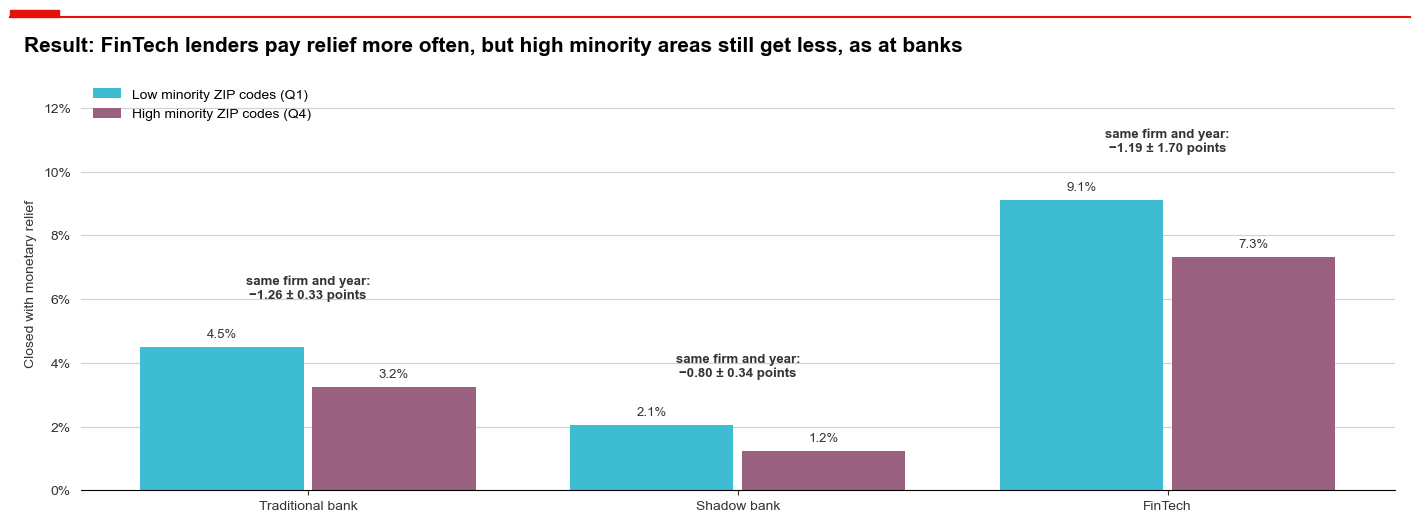

In [15]:
# Appendix A1 of Buchak et al. (2018), as regular expressions on the CFPB company name
LENDER_TYPES = {
    "FinTech": [r"rocket mortgage|quicken", r"amerisave", r"cashcall", r"guaranteed rate", r"homebridge",
                r"movement mortgage"],
    "Shadow bank": [r"academy mortgage", r"amcap", r"american neighborhood", r"american pacific mortgage",
                    r"amerifirst financial", r"amerihome", r"ark-la-tex", r"bay equity", r"broker solutions",
                    r"caliber home", r"chicago mortgage solutions", r"cmg financial", r"ditech", r"fairway independent",
                    r"franklin american", r"freedom mortgage company", r"guild holdings", r"impac mortgage",
                    r"ld holdings|loandepot", r"mortgage research center", r"nationstar|mr\. cooper",
                    r"pacific union", r"pennymac", r"phh mortgage", r"plaza home", r"primary residential",
                    r"primelending", r"prospect mortgage", r"provident funding", r"sierra pacific", r"sovereign lending",
                    r"stearns", r"stonegate", r"united shore", r"walker (and|&) dunlop"],
    "Traditional bank": [r"ally financial", r"bank of america", r"bok financial", r"branch banking|^bb&t",
                         r"suntrust|truist", r"capital one", r"citibank|citigroup|citimortgage", r"everbank",
                         r"fifth third", r"first republic", r"flagstar", r"fremont bank", r"homestreet",
                         r"hsbc", r"jpmorgan chase", r"metlife", r"morgan stanley", r"mufg|union bank",
                         r"navy federal", r"new york community|ny community", r"pnc bank", r"redwood credit",
                         r"regions financial|regions bank", r"union savings bank", r"u\.s\. bancorp",
                         r"united services automobile", r"wells fargo"],
}
LENDER_ORDER = ["Traditional bank", "Shadow bank", "FinTech"]


def lender_type(company):
    '''Return the type of a lender from its CFPB name, or missing if it is not on the list.'''
    name = company.lower()
    for kind, patterns in LENDER_TYPES.items():
        if any(re.search(pattern, name) for pattern in patterns):
            return kind
    return np.nan


mortgages = in_years[in_years["product_group"] == "Mortgage"].copy()
types = {name: lender_type(name) for name in mortgages["company"].astype(str).unique()}
mortgages["lender_type"] = mortgages["company"].astype(str).map(types)
classified = mortgages.dropna(subset=["lender_type"])

fintech = classified[classified["lender_type"] == "FinTech"]
print(f"Classified: {len(classified) / len(mortgages):.1%} of {len(mortgages):,} mortgage complaints; "
      f"FinTech {len(fintech):,}, of which Rocket Mortgage {fintech['company'].eq('Rocket Mortgage, LLC').mean():.1%}")
print("Share from the highest minority quartile:",
      classified.groupby("lender_type")["minority_q"].apply(lambda q: f"{(q == 4).mean():.1%}").to_dict())

lender_gaps = pd.DataFrame({kind: minority_gaps(classified[classified["lender_type"] == kind], ["company", "year"]).loc[4]
                            for kind in LENDER_ORDER}).T
relief = classified[classified["closed"] & classified["minority_q"].isin([1, 4])].groupby(
    ["lender_type", "minority_q"])["relief"].mean().unstack().loc[LENDER_ORDER]

fig, ax = plt.subplots(figsize=(14, 5))
positions = np.arange(len(LENDER_ORDER))
for shift, quartile, label, color in [(-0.2, 1, "Low minority ZIP codes (Q1)", CYAN),
                                      (0.2, 4, "High minority ZIP codes (Q4)", PURPLE)]:
    bars = ax.bar(positions + shift, relief[quartile], width=0.38, color=color, label=label)
    for bar, value in zip(bars, relief[quartile]):
        annotate(ax, f"{value:.1%}", (bar.get_x() + bar.get_width() / 2, value), offset=(0, 9))
for position, kind in zip(positions, LENDER_ORDER):
    gap, error = lender_gaps.loc[kind]
    annotate(ax, minus_sign(f"same firm and year:\n{gap * 100:+.2f} ± {Z_95 * error * 100:.2f} points"),
             (position, relief.loc[kind].max()), offset=(0, 42), fontweight="bold")
ax.set_xticks(positions, LENDER_ORDER)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.13)
ax.set_ylabel("Closed with monetary relief")
ax.legend(loc="upper left")
show("Result: FinTech lenders pay relief more often, but high minority areas still get less, as at banks")

**Comments – 3.B.1**
* **More relief for everyone, same gap:** FinTech lenders pay relief twice as often as banks (9.1% against 4.5% in low minority areas), and their minority gap (−1.19 ± 1.70 points) is close to the banks' (−1.26 ± 0.33), though too noisy to tell from zero.
* **Caveat:** Rocket Mortgage (formerly Quicken Loans) is 65.6% of the FinTech group, and all three types draw a similar share of complaints from high minority areas (26.5% to 29.4%).

#### 3.B.2 AI-empowered against other banks
**Measure.** As the slides suggest, we asked a large language model (Claude) when each large bank launched a **customer-facing conversational AI assistant**, and kept only the answers it gave with high confidence (Bank of America's checked against the press release in the slides): Capital One (Eno, 2017), Bank of America (Erica, 2018), U.S. Bank (Smart Assistant, 2020), Wells Fargo (Fargo, generative AI, 2023). JPMorgan Chase and Citibank had none in the US and are the controls; other banks are left out.

**Test.** Difference in differences of the minority relief gap (Q4 against Q1) around launch:

relief = β · high minority × after launch + bank × product × year + high minority × (bank + year + product) + error.

β < 0 means the gap widens after launch beyond what the control banks see in the same year.

β = −0.05 points (95%: −1.54 to +1.45), 262,475 complaints; leaving out one bank: −0.75 to +0.73


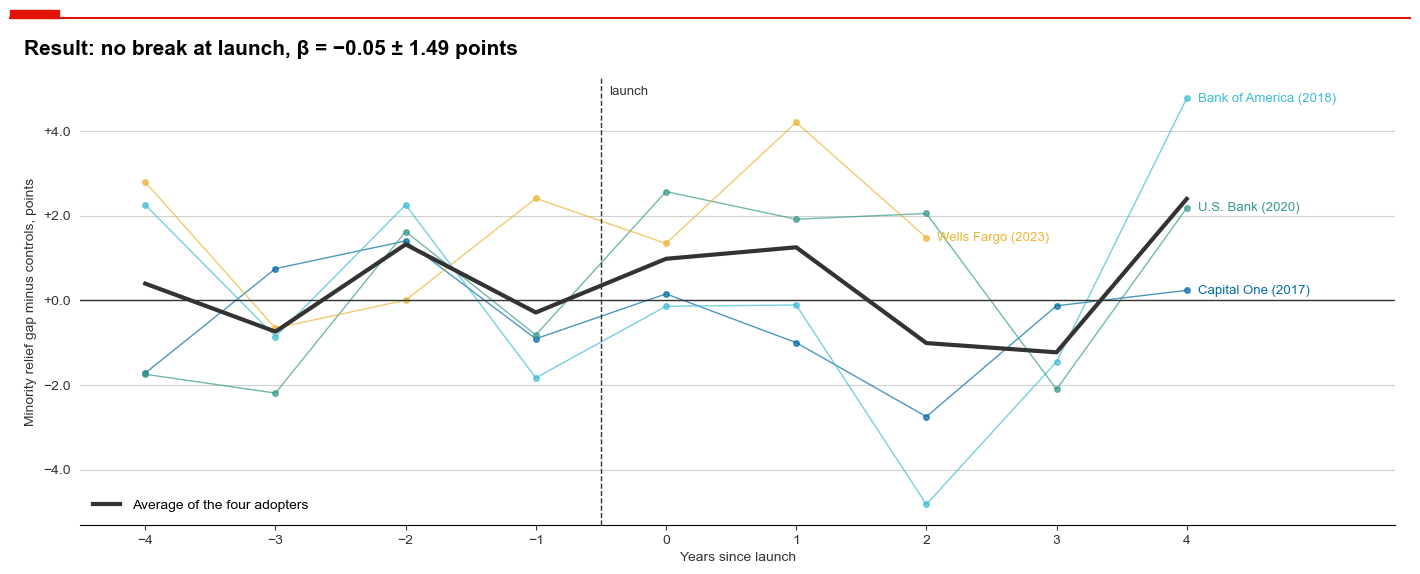

In [16]:
AI_LAUNCH = {  # CFPB company name: (short name, launch year of the assistant; missing = control)
    "CAPITAL ONE FINANCIAL CORPORATION": ("Capital One", 2017),
    "BANK OF AMERICA, NATIONAL ASSOCIATION": ("Bank of America", 2018),
    "U.S. BANCORP": ("U.S. Bank", 2020),
    "WELLS FARGO & COMPANY": ("Wells Fargo", 2023),
    "JPMORGAN CHASE & CO.": ("JPMorgan Chase", np.nan),
    "CITIBANK, N.A.": ("Citibank", np.nan),
}
DID_FORMULA = ("relief ~ high_minority:post_ai + C(cell) + C(bank):high_minority"
               " + C(year):high_minority + C(product_group):high_minority")
EVENT_WINDOW = range(-4, 5)  # years around launch

in_banks = in_years["company"].isin(list(AI_LAUNCH)) & in_years["minority_q"].isin([1, 4]) & in_years["closed"]
banks = in_years[in_banks].assign(product_group=lambda t: t["product_group"].astype(str))
banks["bank"] = banks["company"].astype(str).map(lambda name: AI_LAUNCH[name][0])
launch = dict(AI_LAUNCH.values())
banks["high_minority"] = (banks["minority_q"] == 4) * 1.0
banks["post_ai"] = (banks["year"] >= banks["bank"].map(launch)) * 1.0  # always 0 for the controls

ai_cells = banks.groupby(["bank", "product_group", "year", "high_minority"]).agg(
    relief=("relief", "mean"), complaints=("relief", "size"), post_ai=("post_ai", "first")).reset_index()
ai_cells["cell"] = ai_cells["bank"] + "|" + ai_cells["product_group"] + "|" + ai_cells["year"].astype(str)


def did(cells):
    '''β of the difference in differences, and its standard error (HC1).'''
    model = smf.wls(DID_FORMULA, data=cells, weights=cells["complaints"]).fit(cov_type="HC1")
    return model.params["high_minority:post_ai"], model.bse["high_minority:post_ai"]


beta, error = did(ai_cells)
leave_one_out = [did(ai_cells[ai_cells["bank"] != bank])[0] for bank in launch]
print(minus_sign(f"β = {beta * 100:+.2f} points (95%: {(beta - Z_95 * error) * 100:+.2f} to {(beta + Z_95 * error) * 100:+.2f}), "
                 f"{len(banks):,} complaints; leaving out one bank: {min(leave_one_out) * 100:+.2f} to {max(leave_one_out) * 100:+.2f}"))

# Event study: each adopter's gap within product, minus the controls' gap in the same year
wide = ai_cells.pivot_table(index=["bank", "year", "product_group"], columns="high_minority",
                            values=["relief", "complaints"]).dropna()
weight = wide[("complaints", 0.0)] + wide[("complaints", 1.0)]
gap = (wide[("relief", 1.0)] - wide[("relief", 0.0)]) * weight
gap_by_year = (gap.groupby(level=["bank", "year"]).sum() / weight.groupby(level=["bank", "year"]).sum()).unstack("bank")
controls = gap_by_year[["JPMorgan Chase", "Citibank"]].mean(axis=1)
adopters = [bank for bank, year in launch.items() if not np.isnan(year)]
event = pd.DataFrame({bank: (gap_by_year[bank] - controls).rename(lambda year: year - launch[bank])
                      for bank in adopters}).reindex(list(EVENT_WINDOW))
average = event.mean(axis=1)

fig, ax = plt.subplots()
for bank, color in zip(adopters, [BLUE, CYAN, TEAL, YELLOW]):
    ax.plot(event.index, event[bank], color=color, lw=1, marker="o", ms=4, alpha=0.7)
    last = event[bank].last_valid_index()
    annotate(ax, f"{bank} ({launch[bank]:.0f})", (last, event[bank][last]), offset=(8, 0), color=color)
ax.plot(average.index, average, color=DARK, lw=3, label="Average of the four adopters")
ax.axvline(-0.5, color=DARK, ls="--", lw=1)
annotate(ax, "launch", (-0.5, ax.get_ylim()[1]), offset=(6, -10), ha="left")
ax.axhline(0, color=DARK, lw=1)
ax.yaxis.set_major_formatter(POINTS)
ax.set_xticks(list(EVENT_WINDOW))
ax.set_xlim(-4.5, 5.6)  # room for the labels
ax.set_xlabel("Years since launch")
ax.set_ylabel("Minority relief gap minus controls, points")
ax.legend(loc="lower left")
show(minus_sign(f"Result: no break at launch, β = {beta * 100:+.2f} ± {Z_95 * error * 100:.2f} points"))

**Comments – 3.B.2**
* **No detectable effect:** the gap does not change at launch (−0.05 ± 1.49 points, every leave-one-out estimate between −0.75 and +0.73). Without the year × minority effects, β would be −1.64 and look significant, but that only picks up the gap widening at all six banks after 2019 (from about −1 to −5 points).
* **Limits:** four adopters and two controls make the errors optimistic, and relief after a complaint is not the conversation itself, which the missing narratives hide.

## Conclusion

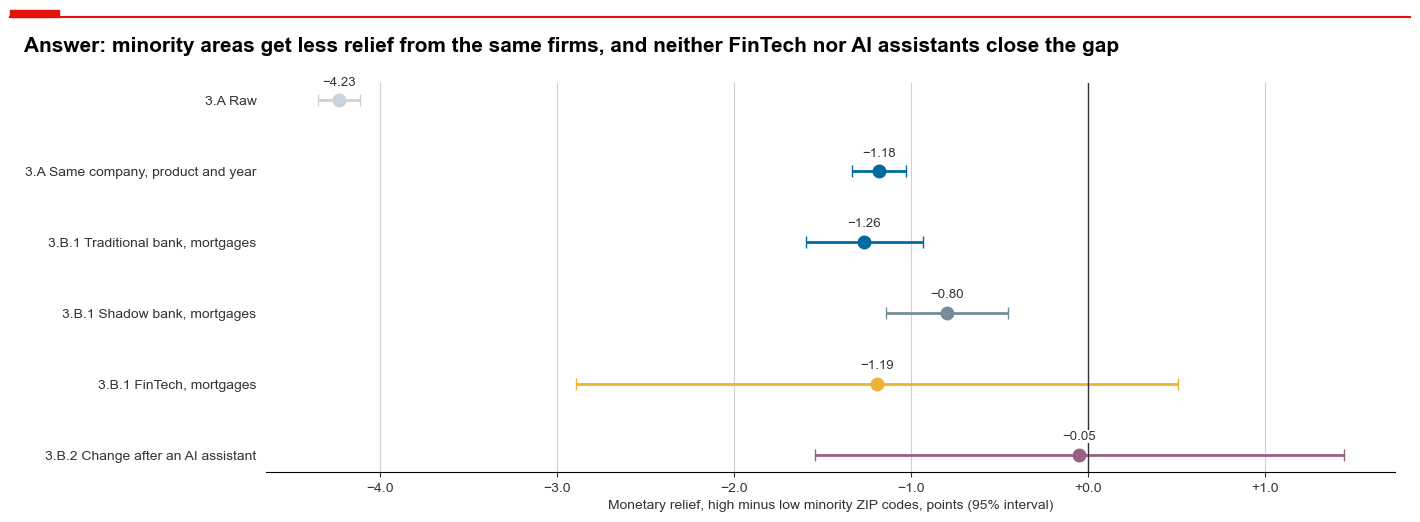

In [17]:
ladder = pd.DataFrame({
    "3.A Raw": raw_gaps.loc[4],
    "3.A Same company, product and year": firm_gaps.loc[4],
    **{f"3.B.1 {kind}, mortgages": lender_gaps.loc[kind] for kind in LENDER_ORDER},
    "3.B.2 Change after an AI assistant": pd.Series({"gap": beta, "error": error}),
}).T

fig, ax = plt.subplots(figsize=(14, 5))
rows = np.arange(len(ladder))[::-1]
colors = [LIGHT_GREY, BLUE, BLUE, GREY, YELLOW, PURPLE]
for row, (name, (gap, err)), color in zip(rows, ladder.iterrows(), colors):
    ax.errorbar(gap, row, xerr=Z_95 * err, fmt="o", color=color, ms=9, capsize=4, lw=2)
    annotate(ax, minus_sign(f"{gap * 100:+.2f}"), (gap, row), offset=(0, 13), bbox=WHITE_BOX)
ax.axvline(0, color=DARK, lw=1)
ax.set_yticks(rows, ladder.index)
ax.xaxis.set_major_formatter(POINTS)
ax.set_xlabel("Monetary relief, high minus low minority ZIP codes, points (95% interval)")
vertical_grid(ax)
show("Answer: minority areas get less relief from the same firms, and neither FinTech nor AI assistants close the gap")

* **Main issues (Task #1):** debt collection (36.8%), cards and bank accounts. Credit reporting (82.4% of all) concerns three bureaus and is filed in bulk, so we leave it out.
* **Lower income customers (Task #2)** complain less per household, but more about debt collection, repossession and collectors' threats.
* **Begley and Purnanandam replicate (Task #3.A):** more complaints in minority areas at the same income, and 1.18 points less relief from the same firm.
* **Technology (Task #3.B):** FinTech lenders pay more relief but keep the gap; AI assistants leave it unchanged (−0.05 ± 1.49 points).
* **With more time:** the narratives (from an older copy of the database) would allow the real test: whether the language of a complaint predicts the response more at AI-empowered banks.

## References
* Begley, T. and Purnanandam, A. (2021), Color and credit: Race, regulation, and the quality of financial services, *Journal of Financial Economics* 141, 48–65.
* Buchak, G., Matvos, G., Piskorski, T. and Seru, A. (2018), Fintech, regulatory arbitrage, and the rise of shadow banks, *Journal of Financial Economics* 130, 453–483 (working paper of May 2017, Appendix A1).
* Bank of America (2025), A decade of AI innovation: BofA's virtual assistant Erica surpasses 3 billion client interactions, press release, August.
* Consumer Financial Protection Bureau, Consumer Complaint Database, downloaded 10 November 2026.
* U.S. Census Bureau, American Community Survey 5-year estimates 2011–2023, ZIP code tabulation areas (course file).